In [80]:
import iisignature
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, root_scalar
from scipy.stats import norm
from scipy.interpolate import griddata
import pandas as pd
from sklearn.model_selection import train_test_split
from esig import tosig as ts
import ast
import QuantLib as ql

In [2]:
# Brownin liikkeen polkuja eri diskretisoinneilla

n_vals = [1, 2, 4, 8, 16, 32, 64, 128]
SEED = 42
rng = np.random.default_rng(SEED)
paths = {}
Bpath = np.array([0.0, rng.normal(0, 1)])
paths[1] = Bpath.copy()
for n in n_vals[1:]:
    old_n = len(Bpath) - 1
    new_path = np.zeros(2 * old_n + 1)
    new_path[::2] = Bpath
    dt = 1 / (2 * old_n)
    for i in range(old_n):
        Z = rng.normal(0, 1)

        new_path[2*i + 1] = (
            (Bpath[i] + Bpath[i+1]) / 2
            + np.sqrt(dt / 4) * Z
        )
    Bpath = new_path
    paths[2 * old_n] = Bpath.copy()


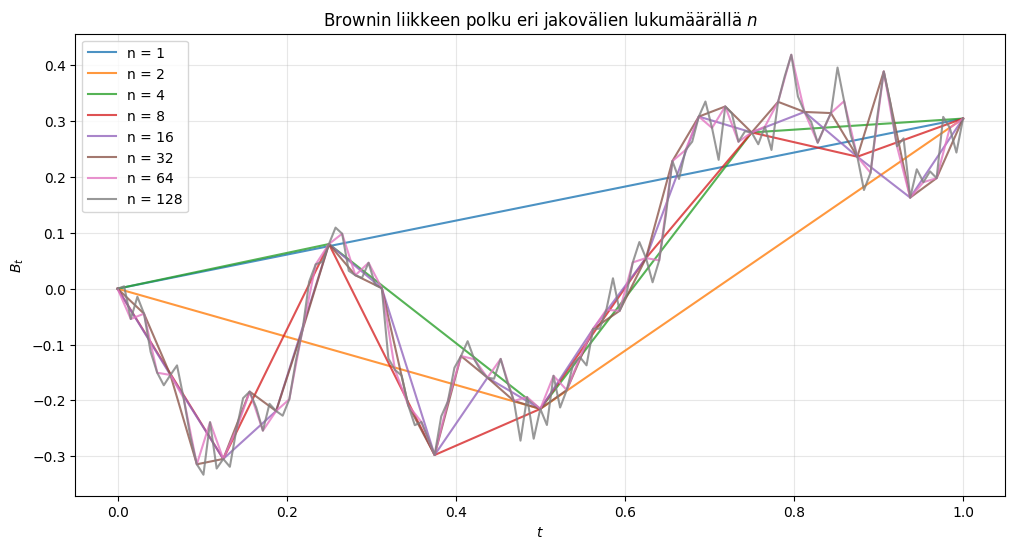

In [3]:
n_max = max(paths.keys())
t_fine = np.linspace(0, 1, n_max + 1)
plt.figure(figsize=(12, 6))
for i in range(len(n_vals)):
    t = np.linspace(0, 1, n_vals[i] + 1)
    B_interp = np.interp(t_fine, t, paths[n_vals[i]])
    
    plt.plot(
        t_fine,
        B_interp,
        label=f"n = {n_vals[i]}",
        alpha=0.8
    )

plt.xlabel("$t$")
plt.ylabel("$B_t$")
plt.title("Brownin liikkeen polku eri jakovälien lukumäärällä $n$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [19]:
# Signatuuriesimerkki yhdelle Brownin liikkeen realisaatiolle
SEED = 202612312412
J = 1000
M = 2
t = np.linspace(0, 1, J)
dt = t[1] - t[0]
rng = np.random.default_rng(SEED)
Z_1 = rng.normal(0, 1, J - 1)
Bpath = np.zeros(J)
Bpath[1:] = np.cumsum(np.sqrt(dt) * Z_1)
stream = np.column_stack((t, Bpath))
Bsig = iisignature.sig(stream, M)
print(Bsig)

[ 1.00000000e+00  2.19402897e-02  5.00000000e-01 -4.74240903e-04
  2.24145306e-02  2.40688156e-04]


In [17]:
Bsig.shape

(999, 6)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


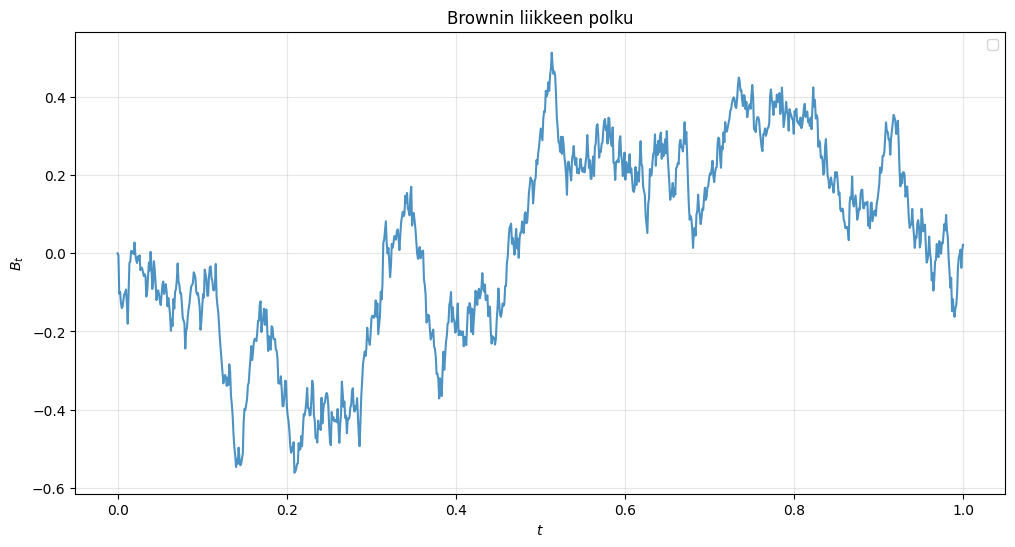

In [6]:
plt.figure(figsize=(12, 6))
plt.plot(
    t,
    Bpath,
    alpha=0.8
)

plt.xlabel("$t$")
plt.ylabel("$B_t$")
plt.title("Brownin liikkeen polku")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# Polkujen simulointi
SEED = 202612312412
J = 250
M = 10
rho = [-1, -0.25, 0, 0.5, 0.75, 1]
Paths = {}
t = np.linspace(0, 1, J)
dt = t[1] - t[0]
rng = np.random.default_rng(SEED)
Z_1 = rng.normal(0, 1, J - 1)
Z_2 = rng.normal(0, 1, J - 1)

sig_size = iisignature.siglength(2, M) + 1

# Volatiliteettiparametrit
sigma = rng.uniform(0, 0.05, sig_size)

# Simuloidaan Brownin liikkeen polut
Bpaths = np.zeros((2, J))
Bpaths[0, 1:] = np.cumsum(np.sqrt(dt) * Z_1)
Bpaths[1, 1:] = np.cumsum(np.sqrt(dt) * Z_2)

# Lasketaan signatuurit
Bsignatures = np.zeros((2, J, sig_size))
Bsignatures[:, :, 0] = 1.0 

for n in range(2):
  stream = np.column_stack((t, Bpaths[n]))
  Bsignatures[n, 1:, 1:] = iisignature.sig(stream, M, 2)

for r in rho:
  path = np.zeros(J)
  path[0] = 1
  for j in range(J - 1):
    sig_j = Bsignatures[0, j]
    sig_dot_sigma = np.dot(sig_j, sigma)
    dW = r * Z_1[j] + np.sqrt(1 - r**2) * Z_2[j]
    path[j + 1] = path[j] * (1 + sig_dot_sigma * dW)

  Paths[r] = path

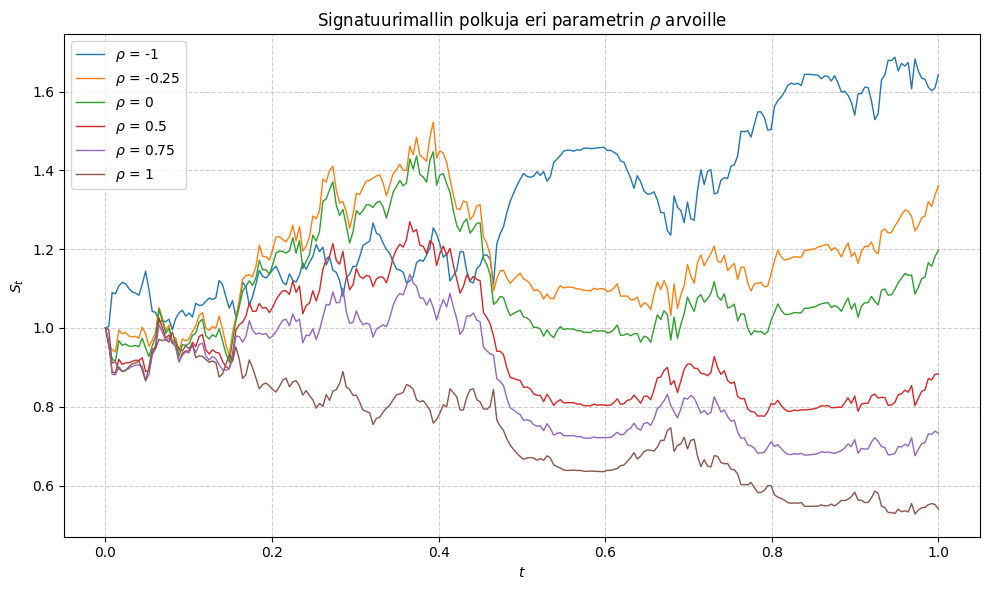

In [10]:
plt.figure(figsize=(10, 6))
for r in rho:
  plt.plot(t, Paths[r], label=f"$\\rho$ = {r}", linewidth=1)

plt.title("Signatuurimallin polkuja eri parametrin $\\rho$ arvoille")
plt.xlabel("$t$")
plt.ylabel("$S_t$")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [2]:
#OU-esimerkki
SEED = 410391249323

J = 1000
N = 1000
M = [1,2,5]
beta1 = 0.05
beta2 = 0.05

ApproxOUPaths = {}

# Simuloidaan N kappaletta Brownin liikkeen polkuja
print(f"Luodaan {N} simulaatiota Brownin liikkeen poluista")
print(f"Status: Työn alla...")
t = np.linspace(0, 1, J)
dt = t[1] - t[0]
rng = np.random.default_rng(SEED)
Z = rng.normal(0, 1, (N, J-1))

Bpaths = np.zeros((N, J))
Bpaths[:, 1:] = np.cumsum(np.sqrt(dt) * Z, axis=1)
print(f"Status: Valmis!")

# Generoidaan OU-prosessit Brownin liikkeistä
print(f"Generoidaan OU-prosessit Brownin liikkeistä")
theta, mu, sigma = 1.0, 0.25, 1.25
OUpaths = np.zeros((N, J))
for j in range(J-1):
  OUpaths[:, j+1] = OUpaths[:, j] + theta * (mu - OUpaths[:, j]) * dt + sigma * np.sqrt(dt) * Z[:, j]

# Generoidaan approksimoitava OU-prosessi
print(f"Generoidaan approksimoitava kohdeprosessi")
TargetZ = rng.normal(0, 1, J-1)
TargetOUpath = np.zeros(J)
for j in range(J-1):
  TargetOUpath[j+1] = TargetOUpath[j] + theta * (mu - TargetOUpath[j]) * dt + sigma * np.sqrt(dt) * TargetZ[j]

# Minimoitava regressiolauseke ja sen gradientti
def objective_and_grad(f, signatures, targetpaths, beta1, beta2):
  predictions = np.tensordot(signatures, f, axes=([2], [0]))
  mse = np.mean((targetpaths - predictions) ** 2)
  penalty = beta1 * np.sum(np.abs(f)) + beta2 * np.sum(f**2)
  obj_value = mse + penalty

  # Lasketaan gradientti
  residuals = predictions - targetpaths
  grad_mse = 2 * np.mean(signatures * residuals[:, :, np.newaxis], axis=(0, 1))
  grad_l1 = beta1 * np.sign(f)
  grad_l2 = 2 * beta2 * f
  grad_f = grad_mse + grad_l1 + grad_l2

  return obj_value, grad_f

# Lasketaan regressioparametrit eri katkaisuasteille
for m in M:
  # Lasketaan Brownin liikkeiden signatuurit jokaiselle aika-askeleelle
  print(f"Aloitetaan signatuurien laskeminen katkaisuasteella {m}")
  sig_size = iisignature.siglength(2, m) + 1

  Bsignatures = np.zeros((N, J, sig_size))
  Bsignatures[:, :, 0] = 1.0

  for n in range(N):
    stream = np.column_stack((t, Bpaths[n]))
    Bsignatures[n, 1:, 1:] = iisignature.sig(stream, m, 2)

  # Etsitään argmin f
  print(f"Etsitään regressioparametrit")
  x0 = np.random.uniform(-1,1,sig_size)
  OptimResult = minimize(objective_and_grad, x0=x0, args=(Bsignatures, OUpaths, beta1, beta2), method="L-BFGS-B", jac=True)
  fstar = OptimResult.x
  print(f"Regressioparametrit löydetty!")

  TargetStream = np.column_stack((t, TargetOUpath))
  Targetsignatures = np.zeros((J, sig_size))
  Targetsignatures[:, 0] = 1.0
  Targetsignatures[1:, 1:] = iisignature.sig(TargetStream, m, 2)

  # Lasketaan regressiopolku matriisi-vektori-tulolla
  print(f"Lasketaan regressiopolku")
  ApproxPath = Targetsignatures @ fstar
  ApproxOUPaths[m] = ApproxPath
  print(f"Approksimointiprosessi valmis!")

Luodaan 1000 simulaatiota Brownin liikkeen poluista
Status: Työn alla...
Status: Valmis!
Generoidaan OU-prosessit Brownin liikkeistä
Generoidaan approksimoitava kohdeprosessi
Aloitetaan signatuurien laskeminen katkaisuasteella 1
Etsitään regressioparametrit
Regressioparametrit löydetty!
Lasketaan regressiopolku
Approksimointiprosessi valmis!
Aloitetaan signatuurien laskeminen katkaisuasteella 2
Etsitään regressioparametrit
Regressioparametrit löydetty!
Lasketaan regressiopolku
Approksimointiprosessi valmis!
Aloitetaan signatuurien laskeminen katkaisuasteella 5
Etsitään regressioparametrit
Regressioparametrit löydetty!
Lasketaan regressiopolku
Approksimointiprosessi valmis!


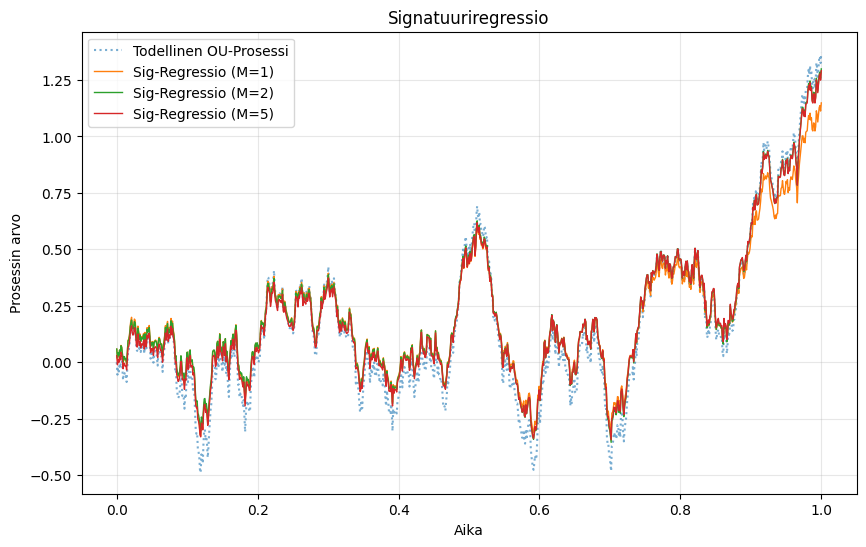

In [3]:
# Luodaan kuvaaja
plt.figure(figsize=(10, 6))
plt.plot(t, TargetOUpath, linestyle="dotted", label="Todellinen OU-Prosessi", alpha=0.6)
for m in M:
  plt.plot(t, ApproxOUPaths[m], label=f"Sig-Regressio (M={m})", linewidth=1)
plt.title(f"Signatuuriregressio")
plt.xlabel("Aika")
plt.ylabel("Prosessin arvo")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [4]:
print("--- Mean Squared Error (MSE) for each M ---")
for m in M:
  mse = np.mean((TargetOUpath - ApproxOUPaths[m]) ** 2)
  print(f"M={m}: MSE = {mse:.5e}")

--- Mean Squared Error (MSE) for each M ---
M=1: MSE = 6.34401e-03
M=2: MSE = 3.88470e-03
M=5: MSE = 3.26196e-03


In [10]:
#GBM-esimerkki
SEED = 8598433798

J = 1000
N = 1000
M = [1,2,5]
beta1 = 0.05
beta2 = 0.05

ApproxGBMPaths = {}

rng = np.random.default_rng(SEED)

# Simuloidaan N kappaletta Brownin liikkeen polkuja
print(f"Luodaan {N} simulaatiota Brownin liikkeen poluista")
print(f"Status: Työn alla...")
t = np.linspace(0, 1, J)
dt = t[1] - t[0]
rng = np.random.default_rng(SEED)
Z = rng.normal(0, 1, (N, J-1))

Bpaths = np.zeros((N, J))
Bpaths[:, 1:] = np.cumsum(np.sqrt(dt) * Z, axis=1)
print(f"Status: Valmis!")

# Generoidaan GBM-prosessit Brownin liikkeistä
print(f"Generoidaan GBM-prosessit Brownin liikkeistä")
mu, sigma = 0.15, 0.25
GBMpaths = np.zeros((N, J))
GBMpaths[:, 0] = 1.0
for j in range(J-1):
  GBMpaths[:, j+1] = GBMpaths[:, j] * (1 + mu * dt + sigma * np.sqrt(dt) * Z[:, j])

# Generoidaan approksimoitava GBM-prosessi
print(f"Generoidaan approksimoitava kohdeprosessi")
TargetZ = rng.normal(0, 1, J-1)
TargetGBMpath = np.zeros(J)
TargetGBMpath[0] = 1.0
for j in range(J-1):
  TargetGBMpath[j+1] = TargetGBMpath[j] * (1 + mu * dt + sigma * np.sqrt(dt) * TargetZ[j])

# Minimoitava regressiolauseke ja sen gradientti
def regressfunc_w_grad(f, signatures, targetpaths, beta1, beta2):
  predictions = np.tensordot(signatures, f, axes=([2], [0]))
  mse = np.mean((targetpaths - predictions) ** 2)
  penalty = beta1 * np.sum(np.abs(f)) + beta2 * np.sum(f**2)
  obj_value = mse + penalty

  # Lasketaan gradientti
  residuals = predictions - targetpaths
  grad_mse = 2 * np.mean(signatures * residuals[:, :, np.newaxis], axis=(0, 1))
  grad_l1 = beta1 * np.sign(f)
  grad_l2 = 2 * beta2 * f
  grad_f = grad_mse + grad_l1 + grad_l2

  return obj_value, grad_f

# Lasketaan regressioparametrit eri katkaisuasteille
for m in M:
  # Lasketaan Brownin liikkeiden signatuurit jokaiselle aika-askeleelle
  print(f"Lasketaan signatuurit katkaisuasteella {m}")
  sig_size = iisignature.siglength(2, m) + 1

  Bsignatures = np.zeros((N, J, sig_size))
  Bsignatures[:, :, 0] = 1.0

  for n in range(N):
    stream = np.column_stack((t, Bpaths[n]))
    Bsignatures[n, 1:, 1:] = iisignature.sig(stream, m, 2)

  # Etsitään argmin f
  print(f"Etsitään regressioparametrit")
  x0 = np.random.uniform(-1,1,sig_size)
  OptimResult = minimize(regressfunc_w_grad, x0=x0, args=(Bsignatures, Bpaths, beta1, beta2), method="L-BFGS-B", jac=True)
  fstar_gbm = OptimResult.x
  print(f"Regressioparametrit löydetty!")

  TargetStream = np.column_stack((t, TargetGBMpath))
  Targetsignatures = np.zeros((J, sig_size))
  Targetsignatures[:, 0] = 1.0
  Targetsignatures[1:, 1:] = iisignature.sig(TargetStream, m, 2)

  # Lasketaan regressiopolku matriisi-vektori-tulolla
  print(f"Lasketaan regressiopolku")
  ApproxPath = Targetsignatures @ fstar_gbm
  ApproxPath[:] += 1
  ApproxGBMPaths[m] = ApproxPath
  print(f"Approksimointiprosessi valmis!")

Luodaan 1000 simulaatiota Brownin liikkeen poluista
Status: Työn alla...
Status: Valmis!
Generoidaan GBM-prosessit Brownin liikkeistä
Generoidaan approksimoitava kohdeprosessi
Lasketaan signatuurit katkaisuasteella 1
Etsitään regressioparametrit
Regressioparametrit löydetty!
Lasketaan regressiopolku
Approksimointiprosessi valmis!
Lasketaan signatuurit katkaisuasteella 2
Etsitään regressioparametrit
Regressioparametrit löydetty!
Lasketaan regressiopolku
Approksimointiprosessi valmis!
Lasketaan signatuurit katkaisuasteella 5
Etsitään regressioparametrit
Regressioparametrit löydetty!
Lasketaan regressiopolku
Approksimointiprosessi valmis!


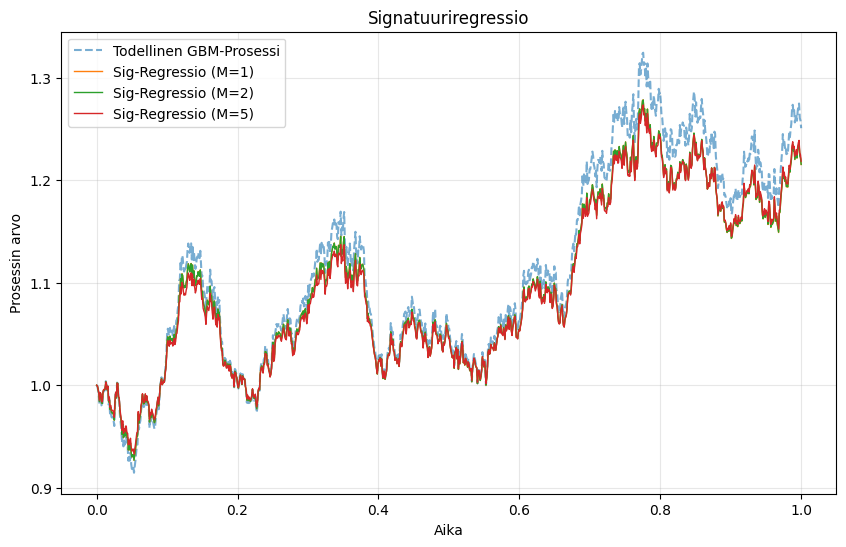

In [11]:
# Luodaan kuvaaja
plt.figure(figsize=(10, 6))
plt.plot(t, TargetGBMpath, linestyle="dashed", label="Todellinen GBM-Prosessi", alpha=0.6)
for m in M:
  plt.plot(t, ApproxGBMPaths[m], label=f"Sig-Regressio (M={m})", linewidth=1)
plt.title(f"Signatuuriregressio")
plt.xlabel("Aika")
plt.ylabel("Prosessin arvo")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [7]:
print("--- Mean Squared Error (MSE) for each M ---")
for m in M:
  mse = np.mean((TargetGBMpath - ApproxGBMPaths[m]) ** 2)
  print(f"M={m}: MSE = {mse:.5e}")

--- Mean Squared Error (MSE) for each M ---
M=1: MSE = 4.32180e-04
M=2: MSE = 4.42533e-04
M=5: MSE = 4.99408e-04


In [ ]:
#GBM-esimerkin jatkoa out-of-sample
SEED = 8598433798

J = 1000
N = 1000
M = [1,2,5]
beta1 = 0.05
beta2 = 0.05

fstar_gbm_dict = {}

rng = np.random.default_rng(SEED)

# Simuloidaan N kappaletta Brownin liikkeen polkuja
print(f"Luodaan {N} simulaatiota Brownin liikkeen poluista")
print(f"Status: Työn alla...")
t = np.linspace(0, 1, J)
dt = t[1] - t[0]
rng = np.random.default_rng(SEED)
Z = rng.normal(0, 1, (N, J-1))

Bpaths = np.zeros((N, J))
Bpaths[:, 1:] = np.cumsum(np.sqrt(dt) * Z, axis=1)
print(f"Status: Valmis!")

# Generoidaan GBM-prosessit Brownin liikkeistä
print(f"Generoidaan GBM-prosessit Brownin liikkeistä")
mu, sigma = 0.15, 0.25
GBMpaths = np.zeros((N, J))
GBMpaths[:, 0] = 1.0
for j in range(J-1):
  GBMpaths[:, j+1] = GBMpaths[:, j] * (1 + mu * dt + sigma * np.sqrt(dt) * Z[:, j])

# Generoidaan approksimoitava GBM-prosessi
print(f"Generoidaan approksimoitava kohdeprosessi")
TargetZ = rng.normal(0, 1, J-1)
TargetGBMpath = np.zeros(J)
TargetGBMpath[0] = 1.0
for j in range(J-1):
  TargetGBMpath[j+1] = TargetGBMpath[j] * (1 + mu * dt + sigma * np.sqrt(dt) * TargetZ[j])

# Minimoitava regressiolauseke ja sen gradientti
def regressfunc_w_grad(f, signatures, targetpaths, beta1, beta2):
  predictions = np.tensordot(signatures, f, axes=([2], [0]))
  mse = np.mean((targetpaths - predictions) ** 2)
  penalty = beta1 * np.sum(np.abs(f)) + beta2 * np.sum(f**2)
  obj_value = mse + penalty

  # Lasketaan gradientti
  residuals = predictions - targetpaths
  grad_mse = 2 * np.mean(signatures * residuals[:, :, np.newaxis], axis=(0, 1))
  grad_l1 = beta1 * np.sign(f)
  grad_l2 = 2 * beta2 * f
  grad_f = grad_mse + grad_l1 + grad_l2

  return obj_value, grad_f

# Lasketaan regressioparametrit eri katkaisuasteille
for m in M:
  # Lasketaan Brownin liikkeiden signatuurit jokaiselle aika-askeleelle
  print(f"Lasketaan signatuurit katkaisuasteella {m}")
  sig_size = iisignature.siglength(2, m) + 1

  Bsignatures = np.zeros((N, J, sig_size))
  Bsignatures[:, :, 0] = 1.0

  for n in range(N):
    stream = np.column_stack((t, Bpaths[n]))
    Bsignatures[n, 1:, 1:] = iisignature.sig(stream, m, 2)

  # Etsitään argmin f
  print(f"Etsitään regressioparametrit")
  x0 = np.random.uniform(-1,1,sig_size)
  OptimResult = minimize(regressfunc_w_grad, x0=x0, args=(Bsignatures, Bpaths, beta1, beta2), method="L-BFGS-B", jac=True)
  fstar_gbm = OptimResult.x
  fstar_gbm_dict[m] = fstar_gbm
  print(f"Regressioparametrit löydetty!")

Luodaan 1000 simulaatiota Brownin liikkeen poluista
Status: Työn alla...
Status: Valmis!
Generoidaan GBM-prosessit Brownin liikkeistä
Generoidaan approksimoitava kohdeprosessi
Lasketaan signatuurit katkaisuasteella 1
Etsitään regressioparametrit
Regressioparametrit löydetty!
Lasketaan signatuurit katkaisuasteella 2
Etsitään regressioparametrit
Regressioparametrit löydetty!
Lasketaan signatuurit katkaisuasteella 5
Etsitään regressioparametrit
Regressioparametrit löydetty!


In [90]:
extension_length = 4
J_ext = extension_length*J
t_extension = np.linspace(0, extension_length+1, J+J_ext)
dt = t[1] - t[0]

SEED = 4112026314

rng = np.random.default_rng(SEED)

TargetZ = rng.normal(0, 1, J_ext-1)

ApproxGBMExtensions = {}

TargetGBMextension = np.zeros(J_ext)
TargetGBMextension[0] = TargetGBMpath[-1]
for j in range(J_ext-1):
  TargetGBMextension[j+1] = TargetGBMextension[j] * (1 + mu * dt + sigma * np.sqrt(dt) * TargetZ[j])

full_gbm_path = np.concatenate((TargetGBMpath, TargetGBMextension))

for m in M:
  sig_size = iisignature.siglength(2, m) + 1
  TargetStream = np.column_stack((t_extension, full_gbm_path))
  Targetsignatures = np.zeros((len(full_gbm_path), sig_size))
  Targetsignatures[:, 0] = 1.0
  Targetsignatures[1:, 1:] = iisignature.sig(TargetStream, m, 2)
  # Lasketaan regressiopolku matriisi-vektori-tulolla
  print(f"Lasketaan regressiopolku")
  ApproxPath = Targetsignatures @ fstar_gbm_dict[m]
  ApproxPath[:] += 1
  ApproxGBMExtensions[m] = ApproxPath
  print(f"Approksimointiprosessi valmis!")

Lasketaan regressiopolku
Approksimointiprosessi valmis!
Lasketaan regressiopolku
Approksimointiprosessi valmis!
Lasketaan regressiopolku
Approksimointiprosessi valmis!


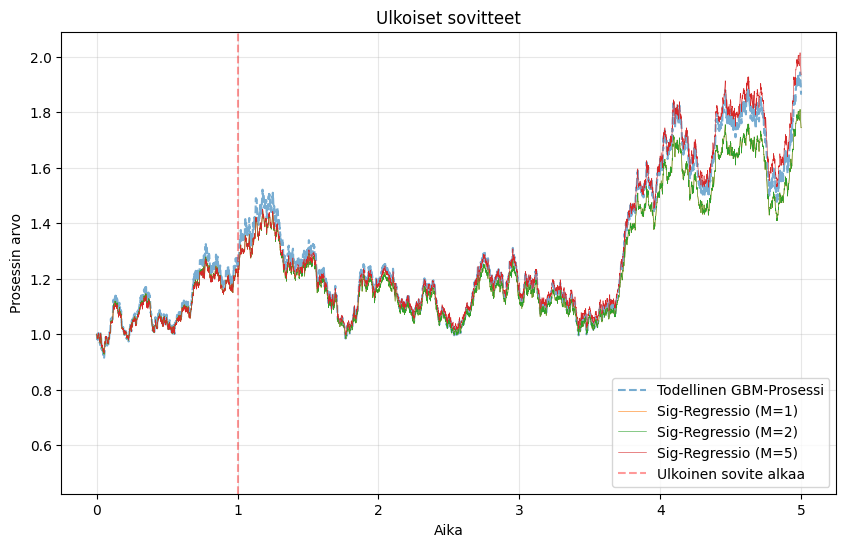

In [95]:
# Luodaan kuvaaja
plt.figure(figsize=(10, 6))
plt.plot(t_extension, full_gbm_path, linestyle="dashed", label="Todellinen GBM-Prosessi", alpha=0.6)
for m in M:
  plt.plot(t_extension, ApproxGBMExtensions[m], label=f"Sig-Regressio (M={m})", linewidth=0.4)
plt.axline((1,0.5),(1,1), linestyle="dashed", label="Ulkoinen sovite alkaa", alpha=0.4, color="r")
plt.title(f"Ulkoiset sovitteet")
plt.xlabel("Aika")
plt.ylabel("Prosessin arvo")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [98]:
print("--- Mean Squared Error (MSE) for each M ---")
for index in range(2*J,2*J+extension_length*J,J):
  print(index)
  for m in M:
    mse = np.mean((full_gbm_path[index-100:index] - ApproxGBMExtensions[m][index-100:index]) ** 2)
    print(f"M={m}: MSE = {mse:.5e}")

--- Mean Squared Error (MSE) for each M ---
2000
M=1: MSE = 7.71050e-04
M=2: MSE = 7.72224e-04
M=5: MSE = 8.23593e-05
3000
M=1: MSE = 1.03595e-03
M=2: MSE = 1.03528e-03
M=5: MSE = 2.57077e-05
4000
M=1: MSE = 5.90151e-03
M=2: MSE = 5.86173e-03
M=5: MSE = 1.12622e-04
5000
M=1: MSE = 1.30583e-02
M=2: MSE = 1.29452e-02
M=5: MSE = 4.30818e-03


In [2]:
data = pd.read_csv("data.csv", sep="\t", header=0)
X_data = data[["time_to_maturity","strike"]]
y_data = data[["mid"]]
X_train, X_test, y_train, y_test = train_test_split(X_data, y_data, test_size=0.1, random_state=42)
S0 = 81.98
quote_data = pd.concat(
    [X_train, y_train],
    axis=1
).reset_index(drop=True)
test_data = pd.concat(
    [X_test, y_test],
    axis=1
).reset_index(drop=True)

In [4]:
# Alustetaan tarvittavat simulaatiokomponentit
SEED = 2026191111523
M = 5
N = 10000

rng = np.random.default_rng(SEED)

sig_size = iisignature.siglength(2, M) + 1

maturities = [3,10,17,24,38]
signatures = {}
bpath_end = {}
bpath_end_perp = {}

for t in maturities:
    end = t/365
    J = int(50 * t)
    t_space = np.linspace(0, end, J)
    dt = t_space[1] - t_space[0]

    # Simuloidaan Brownin liikkeen polut
    Z1 = rng.normal(0, 1, (N, J-1))
    BMpaths1 = np.zeros((N, J))
    BMpaths1[:, 1:] = np.cumsum(np.sqrt(dt) * Z1, axis=1)
    BMpaths2 = np.sqrt(end) * rng.normal(0, 1, N)

    # Lasketaan Brownin liikkeen signatuurit maturiteetissa
    sigs = np.zeros((N, sig_size))
    sigs[:, 0] = 1.0

    for i in range(N):
        TargetStream = np.column_stack((t_space, BMpaths1[i, :]))
        sigs[i, 1:] = iisignature.sig(TargetStream, M)

    signatures[t] = sigs
    bpath_end[t] = BMpaths1[:,-1]
    bpath_end_perp[t] = BMpaths2

    print(f"Maturiteetti: {t}, Signatuurin koko: {sigs.shape}")

# Alustetaan tarvittavat simulaatiokomponentit testaukselle
SEED = 2026201111523
N = 10000

rng = np.random.default_rng(SEED)
sig_size = iisignature.siglength(2, M) + 1

maturities_test = [3,10,17,24,38]
signatures_test = {}
bpath_end_test = {}
bpath_end_perp_test = {}

for t in maturities_test:
    end = t/365
    J = int(50 * t)
    t_space = np.linspace(0, end, J)
    dt = t_space[1] - t_space[0]

    # Simuloidaan Brownin liikkeen polut
    Z1 = rng.normal(0, 1, (N, J-1))
    BMpaths1_t = np.zeros((N, J))
    BMpaths1_t[:, 1:] = np.cumsum(np.sqrt(dt) * Z1, axis=1)
    BMpaths2_t = np.sqrt(end) * rng.normal(0, 1, N)

    # Lasketaan Brownin liikkeen signatuurit maturiteetissa
    sigs = np.zeros((N, sig_size))
    sigs[:, 0] = 1.0

    for i in range(N):
        TargetStream = np.column_stack((t_space, BMpaths1_t[i, :]))
        sigs[i, 1:] = iisignature.sig(TargetStream, M)

    signatures_test[t] = sigs
    bpath_end_test[t] = BMpaths1_t[:,-1]
    bpath_end_perp_test[t] = BMpaths2_t

    print(f"Maturiteetti: {t}, Signatuurin koko: {sigs.shape}")

Maturiteetti: 3, Signatuurin koko: (10000, 63)
Maturiteetti: 10, Signatuurin koko: (10000, 63)
Maturiteetti: 17, Signatuurin koko: (10000, 63)
Maturiteetti: 24, Signatuurin koko: (10000, 63)
Maturiteetti: 38, Signatuurin koko: (10000, 63)
Maturiteetti: 3, Signatuurin koko: (10000, 63)
Maturiteetti: 10, Signatuurin koko: (10000, 63)
Maturiteetti: 17, Signatuurin koko: (10000, 63)
Maturiteetti: 24, Signatuurin koko: (10000, 63)
Maturiteetti: 38, Signatuurin koko: (10000, 63)


In [5]:
# Hinnoittelufunktioita sekä minimoitava regressiolauseke volatiliteettirajoitteella ja sen gradientti

keys = ts.sigkeys(2,M).strip().split(" ")
tuples = [ast.literal_eval(s) for s in keys]
start_indexes = []
start_indexes.append(2)
for i in range(3,len(tuples)):
    key = tuples[i]
    if key[-1] == 2:
        start_indexes.append(i)

def projection_function(f, start_indexes=start_indexes):
    """
    Muodostetaan projektio kerroinkokoelmasta f kantavektorin e_2 suhteen. Tämä rakenne toimii tällä hetkellä vain kaksiulotteisille poluille.
    """
    f_proj = np.array(f[start_indexes])
    f_proj = np.pad(f_proj, (0, len(f)-len(f_proj)), 'constant')
    return f_proj

def asset_price_at_maturity(f, s0, r, sig, path_end, perp_path_end):
    """
    Kohde-etuuden arvo maturiteetissa yksittäiselle signatuuri-polku-kokoelmalle.
    """
    dW = r * path_end + np.sqrt(1 - r ** 2) * perp_path_end
    price = s0 * (1 + np.dot(f, sig) * dW)
    return price

def mc_call_price(k, f, signatures, s0, r, path_ends, perp_path_ends):
    """
    Option hinta Monte Carlo -menetelmällä jollekin kerroinkokoelmalle, annettuna signatuurit ja polut.
    """
    dW = r * path_ends + np.sqrt(1 - r**2) * perp_path_ends
    coefficients = signatures @ f
    asset_prices = s0 * (1 + coefficients * dW)
    payoffs = np.maximum(asset_prices - k, 0)
    return np.mean(payoffs)

def regressfunc_w_grad(
    f,
    quote_data,
    signatures,
    bpath_end,
    bpath_end_perp,
    s0,
    r,
    beta1,
    beta2
):
    strikes = quote_data["strike"].to_numpy(dtype=float)
    maturities = quote_data["time_to_maturity"].to_numpy(dtype=int)
    target_prices = quote_data["mid"].to_numpy(dtype=float)
    J = len(target_prices)
    predictions = np.zeros(J)
    price_gradients = np.zeros((J, len(f)))

    # Loop through maturities
    for T in np.unique(maturities):
        idx = np.where(maturities == T)[0]
        strikes_T = strikes[idx]

        # Simulations corresponding to maturity T
        sigs = signatures[T]
        path_end = bpath_end[T]
        perp_path_end = bpath_end_perp[T]

        # Correlated Brownian motion
        dW = r * path_end + np.sqrt(1 - r**2) * perp_path_end

        # Simulated underlying prices
        coefficients = sigs @ f
        asset_prices = s0 * (1 + coefficients * dW)
        # Calculate prices and gradients for each strike
        for index, K in zip(idx, strikes_T):
            payoffs = np.maximum(asset_prices - K, 0)
            predictions[index] = np.mean(payoffs)

            # Gradient of Monte Carlo price
            indicator = (asset_prices > K).astype(float)
            gradient = (
                indicator[:, np.newaxis]
                * s0
                * dW[:, np.newaxis]
                * sigs
            )

            price_gradients[index] = np.mean(gradient, axis=0)

    # 1. Mean squared pricing error
    residuals = predictions - target_prices
    mse = np.mean(residuals**2)
    grad_mse = (
        2 / J
        * price_gradients.T @ residuals
    )

    # 2. Lasso penalty
    lasso_penalty = beta1 * np.sum(np.abs(f))
    grad_lasso = beta1 * np.sign(f)

    # 3. Ridge penalty
    ridge_penalty = beta2 * np.sum(f**2)
    grad_ridge = 2 * beta2 * f

    # Total objective
    obj_value = mse + lasso_penalty + ridge_penalty

    # Total gradient
    grad_f = grad_mse + grad_lasso + grad_ridge
    return obj_value, grad_f

def constraint_func(f, signatures):
    f_proj = projection_function(f)

    return np.concatenate([
        signatures[T] @ f_proj
        for T in signatures.keys()
    ])

def constraint_jac(f, signatures):
    constraint_gradients = []

    for T in signatures.keys():
        sigs = signatures[T]

        jac = np.zeros_like(sigs)
        jac[:, start_indexes] = sigs[:, start_indexes]

        constraint_gradients.append(jac)

    return np.vstack(constraint_gradients)

def positivity_constraint(f, signatures, bpath_end,
                          bpath_end_perp, r, epsilon=1e-6):
    values_all = []
    for T in signatures.keys():
        sigs = signatures[T]
        dW = (
            r * bpath_end[T]
            + np.sqrt(1-r**2) * bpath_end_perp[T]
        )
        values = 1 + (sigs @ f) * dW
        values_all.append(values - epsilon)
    return np.concatenate(values_all)

def positivity_constraint_jac(f, signatures, bpath_end,
                              bpath_end_perp, r):
    gradients = []
    for T in signatures.keys():
        sigs = signatures[T]
        dW = (
            r * bpath_end[T]
            + np.sqrt(1-r**2) * bpath_end_perp[T]
        )
        jac = sigs * dW[:, None]
        gradients.append(jac)
    return np.vstack(gradients)

def optimise_signature_regression(
    f0,
    quote_data,
    signatures,
    bpath_end,
    bpath_end_perp,
    beta1,
    beta2,
    s0,
    r
):

    constraints = [
        {
            'type': 'ineq',
            'fun': lambda f: constraint_func(f, signatures),
            'jac': lambda f: constraint_jac(f, signatures)
        },
        {
            'type': 'ineq',
            'fun': lambda f: positivity_constraint(
                f, signatures, bpath_end,
                bpath_end_perp, r
            ),
            'jac': lambda f: positivity_constraint_jac(
                f, signatures, bpath_end,
                bpath_end_perp, r
            )
        }
    ]
    result = minimize(
        fun=regressfunc_w_grad,
        x0=f0,
        args=(
            quote_data,
            signatures,
            bpath_end,
            bpath_end_perp,
            s0,
            r,
            beta1,
            beta2
        ),
        jac=True,
        method='SLSQP',
        constraints=constraints,
        options={
            'maxiter': 10,
            'ftol': 1e-9,
            'disp': True
        }
    )
    return result


In [6]:
SEED = 20112026143822
rng = np.random.default_rng(SEED)

beta1 = 0.05
beta2 = 0.05
rho = [-0.6, -0.7, -0.8]
f_opt = {}
f0 = rng.uniform(0, 0.05, sig_size)

for r in rho:
    result = optimise_signature_regression(
        f0=f0,
        quote_data=quote_data,
        signatures=signatures,
        bpath_end=bpath_end,
        bpath_end_perp=bpath_end_perp,
        beta1=beta1,
        beta2=beta2,
        s0=S0,
        r=r
    )
    f_opt[r] = result.x
    print("Optimization successful:", result.success)
    print("Message:", result.message)
    print("Optimal objective:", result.fun)
    print("Optimal parameters:", f_opt)

Iteration limit reached    (Exit mode 9)
            Current function value: 1.0854458240747782
            Iterations: 10
            Function evaluations: 21
            Gradient evaluations: 10
Optimization successful: False
Message: Iteration limit reached
Optimal objective: 1.0854458240747782
Optimal parameters: {-0.6: array([ 0.59330681, -0.07846273,  0.16997458, -0.11578569, -0.09518366,
       -0.58111273, -0.20583554,  0.25599176, -0.09299349, -0.21406442,
       -0.04618404, -0.24037311, -0.71223417,  0.27661372,  0.7446602 ,
        0.26433203,  0.27164873,  0.26875955,  0.26948633,  0.27025316,
        0.25993953, -0.0016089 ,  0.27228774,  0.26615148,  0.2630812 ,
       -0.20927761,  0.29046697,  0.26480845, -0.07860001, -0.21602427,
        0.01342376, -0.18687525,  0.27013796,  0.26155169, -0.22426783,
       -0.21619078,  0.26469006, -0.21271664, -0.22466435, -0.22184232,
        0.26564608, -0.20568593,  0.26481144,  0.26616485,  0.26438485,
       -0.21595903, -0.210

In [7]:
for i in range(len(rho)):
    test_predictions = []
    for _, row in test_data.iterrows():
        K = row["strike"]
        T = int(row["time_to_maturity"])
        price = mc_call_price(
            K,
            f_opt[rho[i]],
            signatures_test[T],
            S0,
            r,
            bpath_end_test[T],
            bpath_end_perp_test[T]
        )
        test_predictions.append(price)
    label = f"model_price_{i}"
    test_data[label] = test_predictions

In [8]:
for i in range(len(rho)):
    # Calculate errors
    test_data[f"error_{i}"] = (
        test_data[f"model_price_{i}"] - test_data["mid"]
    )
    test_data[f"absolute_error_{i}"] = np.abs(
        test_data[f"error_{i}"]
    )
    test_data[f"squared_error_{i}"] = (
        test_data[f"error_{i}"] ** 2
    )
    # Calculate performance metrics
    print(f"\nrho = {rho[i]}")
    print(
        "Test MAE:",
        test_data[f"absolute_error_{i}"].mean()
    )
    print(
        "Test MSE:",
        np.mean(test_data[f"squared_error_{i}"])
    )


rho = -0.6
Test MAE: 0.2809929613921529
Test MSE: 0.0941542706188172

rho = -0.7
Test MAE: 0.7691900111600654
Test MSE: 1.5139039235043446

rho = -0.8
Test MAE: 0.3599282165585616
Test MSE: 0.18052932153413656


C:\Users\Otso\AppData\Local\Temp\ipykernel_15880\1493741655.py:33: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(


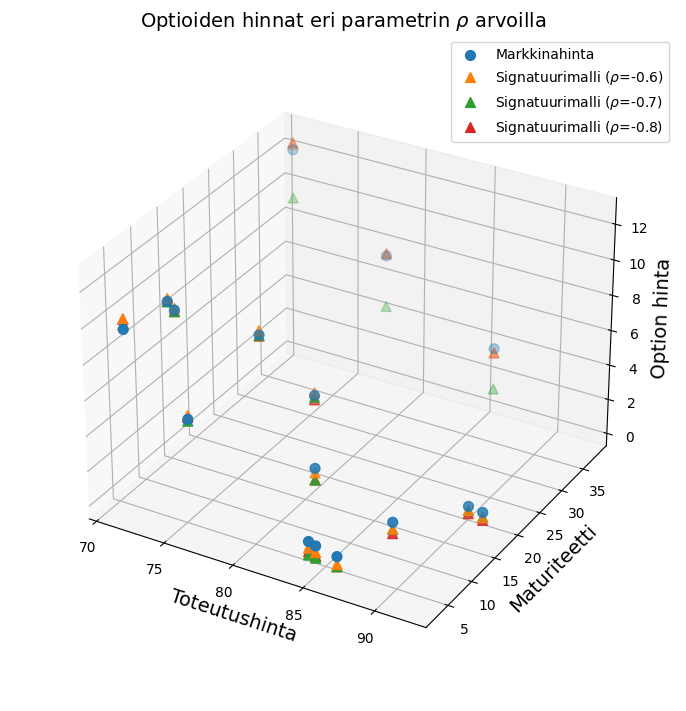

In [9]:
fig = plt.figure(figsize=(12, 7), layout="constrained")
ax = fig.add_subplot(111, projection='3d')

# Market option prices
ax.scatter(
    test_data["strike"],
    test_data["time_to_maturity"],
    test_data["mid"],
    label="Markkinahinta",
    marker="o",
    s=50
)

# Model option prices for each rho
for i in range(len(rho)):
    ax.scatter(
        test_data["strike"],
        test_data["time_to_maturity"],
        test_data[f"model_price_{i}"],
        label=fr"Signatuurimalli ($\rho$={rho[i]})",
        marker="^",
        s=50,
    )

ax.set_xlabel("Toteutushinta", fontsize=14)
ax.set_ylabel("Maturiteetti", fontsize=14)
ax.set_zlabel("Option hinta", fontsize=14)

ax.set_title(r"Optioiden hinnat eri parametrin $\rho$ arvoilla", fontsize=14)
ax.legend()
ax.set_box_aspect(None, zoom=0.9)

fig.subplots_adjust(
    left=0.05,
    right=0.85,
    bottom=0.05,
    top=0.92
)

plt.show()

In [17]:
matur_3 = data[data.time_to_maturity==3]
matur_10 = data[data.time_to_maturity==10]
matur_17 = data[data.time_to_maturity==17]
matur_24 = data[data.time_to_maturity==24]
matur_38 = data[data.time_to_maturity==38]

In [49]:
def black_scholes_call_price(s0, r, t, k, sigma):
    a = 1/(sigma*np.sqrt(t))*(np.log(s0/k)+t*(r+(sigma**2)/2))
    c = s0*norm.cdf(a)-k*np.exp(-r*t)*norm.cdf(a-sigma*np.sqrt(t))
    return c

def objective(sigma, s0, r, t, k, market_price):
    return black_scholes_call_price(s0, r, t, k, sigma) - market_price

def implied_volatility(s0, r, t, k, market_price):
    try:
        result = root_scalar(
            objective,
            args=(s0, r, t, k, market_price),
            bracket=[1e-6, 5],
            method='brentq'
        )
        if result.converged:
            return result.root
        return np.nan
    except (ValueError, RuntimeError):
        return np.nan

In [96]:
iv_data = data.copy()
iv_data["time_to_maturity"] = iv_data["time_to_maturity"] / 365

iv_data['implied_volatility'] = iv_data.apply(
    lambda row: implied_volatility(
        s0=S0,
        r=0,
        t=row["time_to_maturity"],
        k=row["strike"],
        market_price=row["mid"]
    ),
    axis=1
)

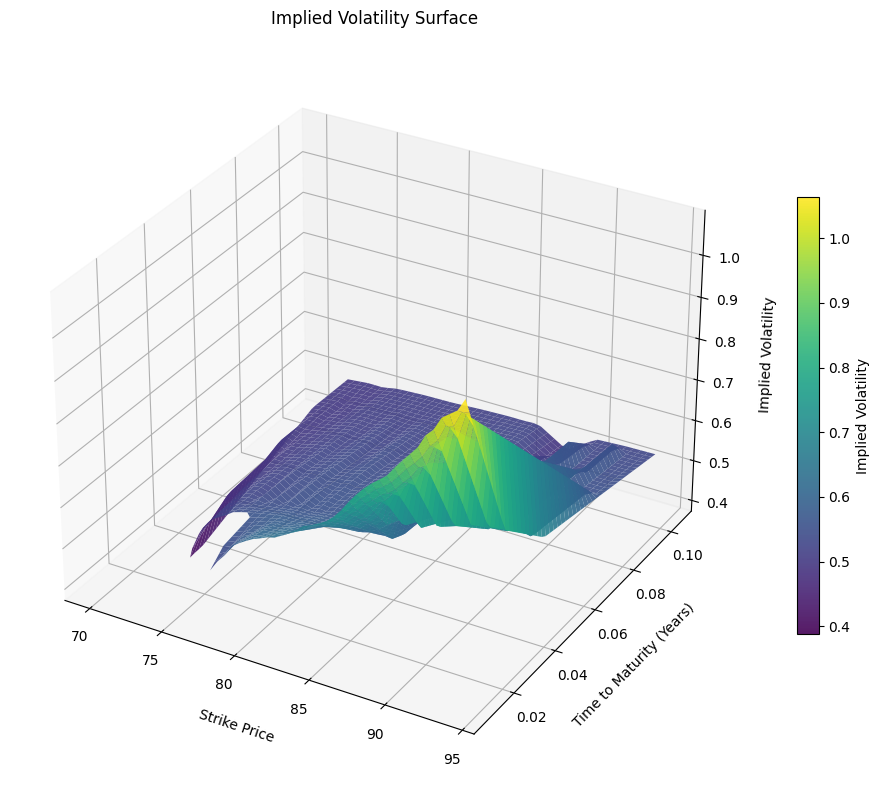

In [97]:
strikes = iv_data["strike"].values
maturities = iv_data["time_to_maturity"].values
vols = iv_data["implied_volatility"].values

# Create a grid
strike_grid = np.linspace(strikes.min(), strikes.max(), 50)
maturity_grid = np.linspace(maturities.min(), maturities.max(), 50)

X, Y = np.meshgrid(strike_grid, maturity_grid)

# Interpolate implied volatilities onto the grid
Z = griddata(
    (strikes, maturities),
    vols,
    (X, Y),
    method='linear'
)

# Create 3D surface plot
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

surface = ax.plot_surface(
    X, Y, Z,
    cmap='viridis',
    edgecolor='none',
    alpha=0.9
)

# Labels
ax.set_xlabel('Strike Price', labelpad=10)
ax.set_ylabel('Time to Maturity (Years)', labelpad=10)
ax.set_zlabel('Implied Volatility', labelpad=10)

ax.set_title('Implied Volatility Surface', pad=20)

# Colorbar
fig.colorbar(surface, ax=ax, shrink=0.6, label='Implied Volatility')

plt.tight_layout()
plt.show()